# Protein embeddings with ESM-2

**Goal:** use a protein language model as a frozen **feature extractor**:

1. Download protein sequences with known labels from UniProt (Swiss-Prot).
2. Run them through a small **ESM-2** model and mean-pool the per-residue vectors → one vector per protein.
3. Project the vectors to 2-D with **UMAP** and color them by label.
4. Train a **logistic regression** on the vectors to predict the label, and compare it with a baseline that doesn't use the model.

There are two tasks:

* **Part A: 6 enzyme families** (kinases, proteases, P450s, …). This is an easy sanity check, because these families look nothing alike.
* **Part B: 6 kinase groups** (AGC, CAMK, CMGC, …). All of them share the same kinase fold, so the task is harder. Model size and baselines start to matter here.

No fine-tuning happens anywhere. The model weights are never updated. See `README.md` for the concepts.

## 0. Setup

In [1]:
from pathlib import Path
import io, time, warnings

import numpy as np
import pandas as pd
import requests
import torch
import matplotlib.pyplot as plt
from transformers import AutoTokenizer, AutoModel
from transformers.utils import logging as hf_logging

hf_logging.set_verbosity_error()
warnings.filterwarnings("ignore", message=".*n_jobs value.*")   # UMAP seed warning
torch.manual_seed(0)
DATA = Path("data"); DATA.mkdir(exist_ok=True)
FIGS = Path("figs"); FIGS.mkdir(exist_ok=True)

# Model choices (all on Hugging Face). Bigger = better embeddings, slower on CPU.
#   facebook/esm2_t6_8M_UR50D     6 layers, 320-dim,   8M params
#   facebook/esm2_t12_35M_UR50D  12 layers, 480-dim,  35M params
#   facebook/esm2_t30_150M_UR50D 30 layers, 640-dim, 150M params
MODEL_NAME = "facebook/esm2_t6_8M_UR50D"

device = "cuda" if torch.cuda.is_available() else ("mps" if torch.backends.mps.is_available() else "cpu")
print("torch", torch.__version__, "| device:", device)

/Users/ynewton/whisker_dx_related/whisker_dx/glm_test/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


torch 2.2.2 | device: cpu


## 1. Get sequences from UniProt

The UniProt REST API returns a TSV. The query keeps only **reviewed** (Swiss-Prot) entries, so the family labels are curated.
Each dataset is cached in `data/<name>.tsv`, so re-running the notebook doesn't hit the API again.

In [2]:
UNIPROT = "https://rest.uniprot.org/uniprotkb/search"
FIELDS = "accession,protein_name,organism_name,length,ec,sequence"

def fetch_dataset(name, families, n_per_family, max_len):
    """families: {short label: UniProt family name}. Returns one row per protein."""
    cache = DATA / f"{name}.tsv"
    if cache.exists():
        return pd.read_csv(cache, sep="\t")
    parts = []
    for label, family in families.items():
        query = f'(family:"{family}") AND (reviewed:true) AND (length:[50 TO {max_len}])'
        r = requests.get(UNIPROT, params={"query": query, "fields": FIELDS,
                                          "format": "tsv", "size": n_per_family}, timeout=60)
        r.raise_for_status()
        parts.append(pd.read_csv(io.StringIO(r.text), sep="\t").assign(family=label))
    df = pd.concat(parts, ignore_index=True).drop_duplicates("Entry").reset_index(drop=True)
    df.to_csv(cache, sep="\t", index=False)
    return df

# Part A: enzyme families, spelled exactly as UniProt's "family" annotation.
ENZYMES = {
    "Kinase":               "Protein kinase superfamily",
    "Serine protease (S1)": "Peptidase S1 family",
    "Cytochrome P450":      "Cytochrome P450 family",
    "SDR":                  "Short-chain dehydrogenases/reductases (SDR) family",
    "α-amylase (GH13)":     "Glycosyl hydrolase 13 family",
    "Aldehyde DH":          "Aldehyde dehydrogenase family",
}
df = fetch_dataset("enzymes", ENZYMES, n_per_family=120, max_len=800)
print(df.shape)
print(df["family"].value_counts())
df.head()

(720, 7)
family
Kinase                  120
Serine protease (S1)    120
Cytochrome P450         120
SDR                     120
α-amylase (GH13)        120
Aldehyde DH             120
Name: count, dtype: int64


,Entry,Protein names,Organism,Length,EC number,Sequence,family
0,Q05823,2-5A-dependent ribonuclease (2-5A-dependent RN...,Homo sapiens (Human),741,3.1.26.-,MESRDHNNPQEGPTSSSGRRAAVEDNHLLIKAVQNEDVDLVQQLLE...,Kinase
1,Q8NB16,Mixed lineage kinase domain-like protein (hMLKL),Homo sapiens (Human),471,NaN,MENLKHIITLGQVIHKRCEEMKYCKKQCRRLGHRVLGLIKPLEMLQ...,Kinase
2,Q7Z7A4,PX domain-containing protein kinase-like prote...,Homo sapiens (Human),578,NaN,MAFMEKPPAGKVLLDDTVPLTAAIEASQSLQSHTEYIIRVQRGISV...,Kinase
3,Q8IZE3,Protein-associating with the carboxyl-terminal...,Homo sapiens (Human),742,NaN,MGSENSALKSYTLREPPFTLPSGLAVYPAVLQDGKFASVFVYKREN...,Kinase
4,Q504Y2,Extracellular tyrosine-protein kinase PKDCC (E...,Homo sapiens (Human),493,2.7.10.2,MRRRRAAVAAGFCASFLLGSVLNVLFAPGSEPPRPGQSPEPSPAPG...,Kinase


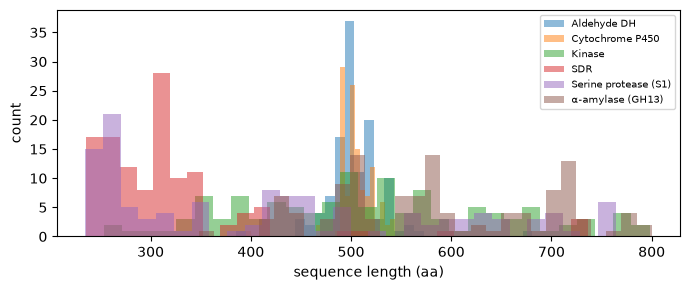

In [3]:
fig, ax = plt.subplots(figsize=(7, 3))
for fam, g in df.groupby("family"):
    ax.hist(g["Length"], bins=30, alpha=0.5, label=fam)
ax.set_xlabel("sequence length (aa)"); ax.set_ylabel("count")
ax.legend(fontsize=7); plt.tight_layout(); plt.show()

## 2. Load ESM-2 and look at what it does to a sequence

ESM-2 is a BERT-style **masked language model** trained on ~65M protein sequences from UniRef50. Its training task was to
predict amino acids that had been hidden from it. To do that well it had to learn which residues co-vary, what
conserved motifs look like, and some structure. None of that training used family labels.

The tokenizer is simple: **one token per amino acid**, plus `<cls>` at the start and `<eos>` at the end.

In [4]:
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
# add_pooling_layer=False: we do our own pooling; the checkpoint has no trained pooler anyway
model = AutoModel.from_pretrained(MODEL_NAME, add_pooling_layer=False).to(device).eval()

n_params = sum(p.numel() for p in model.parameters())
print(f"{MODEL_NAME}: {n_params/1e6:.1f}M params, "
      f"{model.config.num_hidden_layers} layers, hidden size {model.config.hidden_size}")

seq = df.loc[0, "Sequence"][:12]
enc = tokenizer(seq, return_tensors="pt")
print(seq)
print(tokenizer.convert_ids_to_tokens(enc["input_ids"][0]))

facebook/esm2_t6_8M_UR50D: 7.7M params, 6 layers, hidden size 320
MESRDHNNPQEG
['<cls>', 'M', 'E', 'S', 'R', 'D', 'H', 'N', 'N', 'P', 'Q', 'E', 'G', '<eos>']


In [5]:
with torch.no_grad():
    out = model(**enc.to(device))
print("last_hidden_state shape:", tuple(out.last_hidden_state.shape),
      " = (batch, tokens incl. <cls>/<eos>, hidden_dim)")

last_hidden_state shape: (1, 14, 320)  = (batch, tokens incl. <cls>/<eos>, hidden_dim)


## 3. Embed every protein (the "feature extractor" step)

The model outputs one vector **per residue**. To get one vector **per protein**, we **mean-pool** over the real residues
and leave out `<cls>`, `<eos>` and padding. The steps:

* Sort sequences by length before batching, so each batch needs little padding. This makes it much faster.
* Use `torch.no_grad()`, because we never back-propagate. That saves memory and time.
* Cache the result in `data/emb_<dataset>_<model>.npy`.

On a laptop CPU, 720 proteins take about 2 minutes with the 8M model and about 6 minutes with the 35M model.

In [6]:
def embed(sequences, model_name, batch_size=8, max_len=1022):
    tok = AutoTokenizer.from_pretrained(model_name)
    mdl = AutoModel.from_pretrained(model_name, add_pooling_layer=False).to(device).eval()
    order = np.argsort([len(s) for s in sequences])          # short → long
    out = np.zeros((len(sequences), mdl.config.hidden_size), dtype=np.float32)
    t0 = time.time()
    for i in range(0, len(order), batch_size):
        idx = order[i:i + batch_size]
        batch = tok([sequences[j] for j in idx], return_tensors="pt",
                    padding=True, truncation=True, max_length=max_len + 2).to(device)
        with torch.no_grad():
            h = mdl(**batch).last_hidden_state                 # (B, T, D)
        # mask = real residues only: attention_mask minus <cls> (first) and <eos> (last real token)
        mask = batch["attention_mask"].clone()
        mask[:, 0] = 0
        mask[torch.arange(len(idx)), batch["attention_mask"].sum(1) - 1] = 0
        mask = mask.unsqueeze(-1).float()
        out[idx] = ((h * mask).sum(1) / mask.sum(1)).cpu().numpy()
        if (i // batch_size) % 20 == 0:
            print(f"  {i + len(idx)}/{len(sequences)}  ({time.time() - t0:.0f}s)")
    print(f"done in {time.time() - t0:.0f}s")
    return out

def get_embeddings(df, dataset, model_name):
    path = DATA / f"emb_{dataset}_{model_name.split('/')[-1]}.npy"
    if path.exists():
        return np.load(path)
    X = embed(df["Sequence"].tolist(), model_name)
    np.save(path, X)
    return X

X = get_embeddings(df, "enzymes", MODEL_NAME)
y = df["family"].values
print("embedding matrix:", X.shape)

embedding matrix: (720, 320)


## 4. Look at the embedding space with UMAP

UMAP squeezes the 320-D vectors into 2-D while trying to keep each point's nearest neighbors close. **The model
never saw family labels.** If families still form separate islands, the model learned something about protein function
from sequence alone.

The second panel colors the same points by **sequence length**. It checks that the clusters aren't just
"long proteins vs. short proteins".

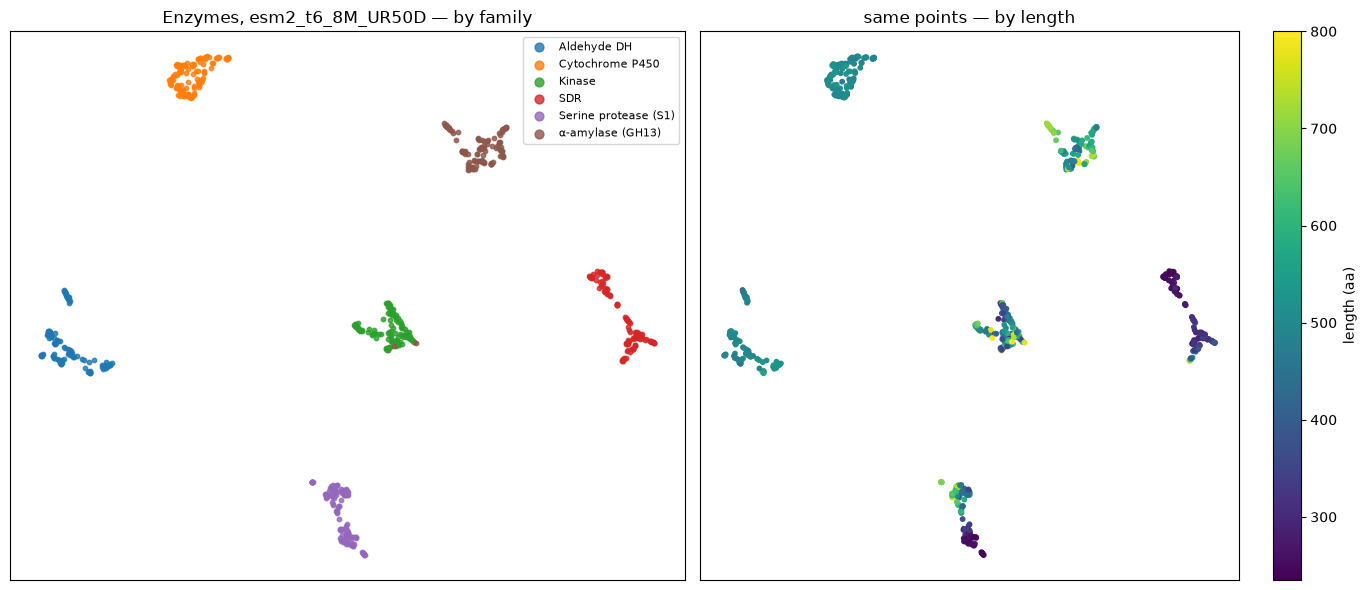

In [7]:
import umap

def plot_umap(X, df, title, fname):
    Z = umap.UMAP(n_neighbors=15, min_dist=0.1, metric="cosine", random_state=42).fit_transform(X)
    labels = df["family"].values
    fams = sorted(set(labels))
    colors = plt.cm.tab10(np.arange(len(fams)))
    fig, axes = plt.subplots(1, 2, figsize=(14, 6))
    for fam, c in zip(fams, colors):
        m = labels == fam
        axes[0].scatter(Z[m, 0], Z[m, 1], s=10, color=c, label=fam, alpha=0.8)
    axes[0].legend(markerscale=2, fontsize=8); axes[0].set_title(f"{title} — by family")
    sc = axes[1].scatter(Z[:, 0], Z[:, 1], s=10, c=df["Length"], cmap="viridis")
    plt.colorbar(sc, ax=axes[1], label="length (aa)"); axes[1].set_title("same points — by length")
    for a in axes: a.set_xticks([]); a.set_yticks([])
    plt.tight_layout(); plt.savefig(FIGS / fname, dpi=120); plt.show()

plot_umap(X, df, f"Enzymes, {MODEL_NAME.split('/')[-1]}", "umap_enzymes.png")

## 5. Linear probe: logistic regression on the embeddings

This is the "foundation model as feature extractor" pattern: **frozen model → fixed vectors → small classic model**.
A *linear* classifier is used on purpose. If a straight-line decision boundary separates the families, the model
has already organized the information. Probing a representation this way is called a **linear probe**.

We use a stratified 75/25 split and standardize the features. `LogisticRegression` handles the 6 classes directly.

                      precision    recall  f1-score   support

         Aldehyde DH      1.000     1.000     1.000        30
     Cytochrome P450      1.000     1.000     1.000        30
              Kinase      1.000     1.000     1.000        30
                 SDR      1.000     1.000     1.000        30
Serine protease (S1)      1.000     1.000     1.000        30
    α-amylase (GH13)      1.000     1.000     1.000        30

            accuracy                          1.000       180
           macro avg      1.000     1.000     1.000       180
        weighted avg      1.000     1.000     1.000       180



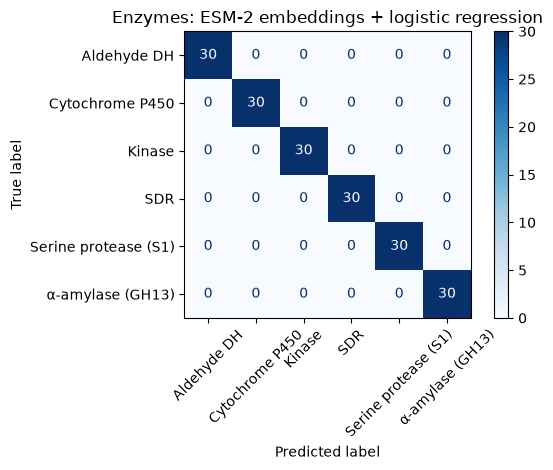

In [8]:
from sklearn.model_selection import train_test_split, cross_val_score, cross_val_predict, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, ConfusionMatrixDisplay

def probe():
    return make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000, C=1.0))

X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.25, stratify=y, random_state=0)
clf = probe().fit(X_tr, y_tr)
print(classification_report(y_te, clf.predict(X_te), digits=3))

ConfusionMatrixDisplay.from_estimator(clf, X_te, y_te, xticks_rotation=45, cmap="Blues")
plt.title("Enzymes: ESM-2 embeddings + logistic regression"); plt.tight_layout(); plt.show()

## 6. Baseline: is the model actually helping?

Always compare against something cheap. Here the baseline is **amino-acid composition**: the fraction of each of the 20
amino acids in the sequence, which gives a 20-D vector with no model involved. If ESM-2 can't beat this baseline,
the "foundation model" isn't adding much.

The comparison uses 5-fold cross-validation, so it doesn't depend on one lucky split.

In [9]:
AA = "ACDEFGHIKLMNPQRSTVWY"
def aa_composition(seqs):
    return np.stack([[s.count(a) / len(s) for a in AA] for s in seqs]).astype(np.float32)

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=0)
def cv_acc(features, y):
    s = cross_val_score(probe(), features, y, cv=cv, scoring="accuracy")
    return s.mean(), s.std()

def compare(df, dataset, models):
    y = df["family"].values
    rows = [("majority class (chance)", pd.Series(y).value_counts(normalize=True).max(), 0.0, 0),
            ("AA composition", *cv_acc(aa_composition(df["Sequence"]), y), 20)]
    for name in models:
        Xm = get_embeddings(df, dataset, name)
        rows.append((name.split("/")[-1], *cv_acc(Xm, y), Xm.shape[1]))
    return pd.DataFrame(rows, columns=["features", "accuracy", "± std", "dim"]).round(3)

compare(df, "enzymes", [MODEL_NAME])

,features,accuracy,± std,dim
0,majority class (chance),0.167,0.000,0
1,AA composition,0.907,0.013,20
2,esm2_t6_8M_UR50D,1.000,0.000,320


ESM-2 gets this almost perfectly right, and even amino-acid composition does well. These families differ in length, fold and
chemistry, so they are easy to tell apart. That makes Part A a good check that the pipeline works, but it doesn't
show much about the model. Part B is harder.

---

# Part B: a harder task, kinase groups

Every protein kinase shares the same ~250-residue catalytic domain. Kinases are divided into **groups**
(AGC, CAMK, CMGC, STE, TK, TKL) by finer differences in that domain and in the regulatory regions around it. A
model has to pick up subtler signals to tell them apart. That makes this a better test of the embeddings, and of
whether the **bigger model** helps.

In [10]:
KINASE_GROUPS = {
    "AGC":  "AGC Ser/Thr protein kinase family",
    "CAMK": "CAMK Ser/Thr protein kinase family",
    "CMGC": "CMGC Ser/Thr protein kinase family",
    "STE":  "STE Ser/Thr protein kinase family",
    "TK":   "Tyr protein kinase family",
    "TKL":  "TKL Ser/Thr protein kinase family",
}
dk = fetch_dataset("kinases", KINASE_GROUPS, n_per_family=100, max_len=1000)
print(dk.shape); print(dk["family"].value_counts())

(600, 7)
family
AGC     100
CAMK    100
CMGC    100
STE     100
TK      100
TKL     100
Name: count, dtype: int64


## 7. Baseline vs. 8M vs. 35M

The first run embeds the kinases with both models, which takes about 10 minutes on CPU. After that the embeddings come from the cache.

In [11]:
MODELS = ["facebook/esm2_t6_8M_UR50D", "facebook/esm2_t12_35M_UR50D"]
compare(dk, "kinases", MODELS)

  8/600  (0s)
  168/600  (17s)
  328/600  (48s)
  488/600  (94s)
done in 147s
  8/600  (1s)
  168/600  (52s)
  328/600  (133s)
  488/600  (263s)
done in 409s


,features,accuracy,± std,dim
0,majority class (chance),0.167,0.000,0
1,AA composition,0.638,0.055,20
2,esm2_t6_8M_UR50D,0.953,0.011,320
3,esm2_t12_35M_UR50D,0.968,0.022,480


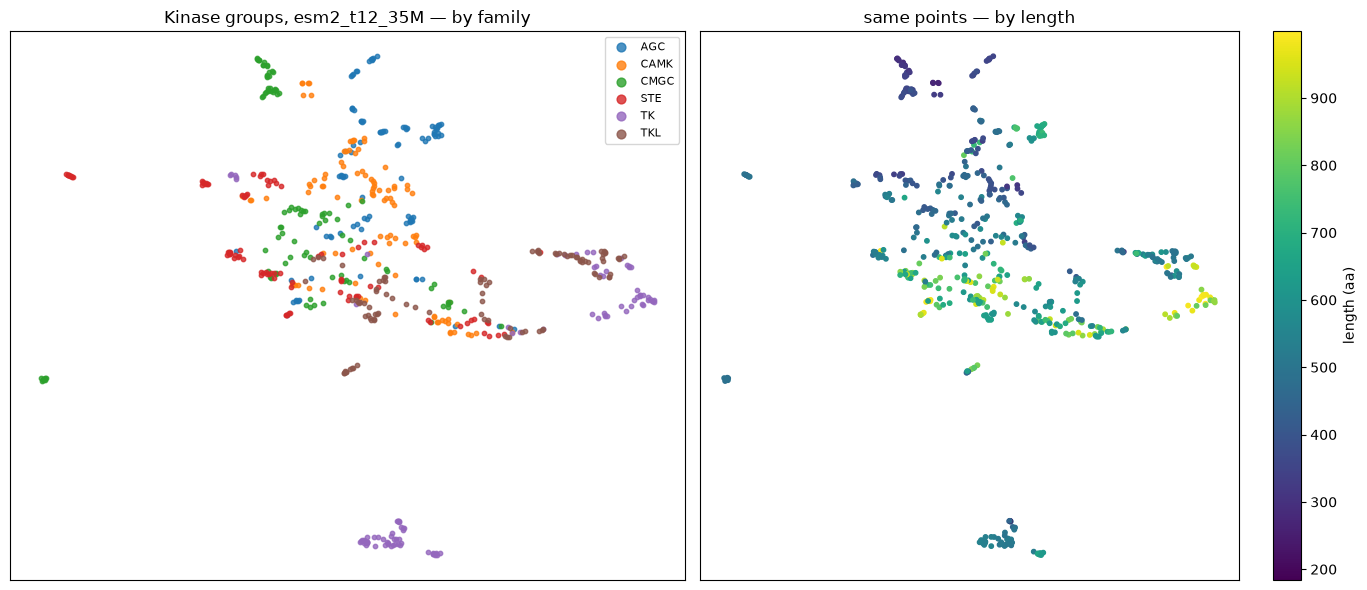

In [12]:
Xk = get_embeddings(dk, "kinases", "facebook/esm2_t12_35M_UR50D")
plot_umap(Xk, dk, "Kinase groups, esm2_t12_35M", "umap_kinases.png")

## 8. Which kinases does it confuse?

The confusion matrix shows which groups blur together. The misclassified list is often the most interesting output:
it tends to contain atypical or multi-domain kinases.

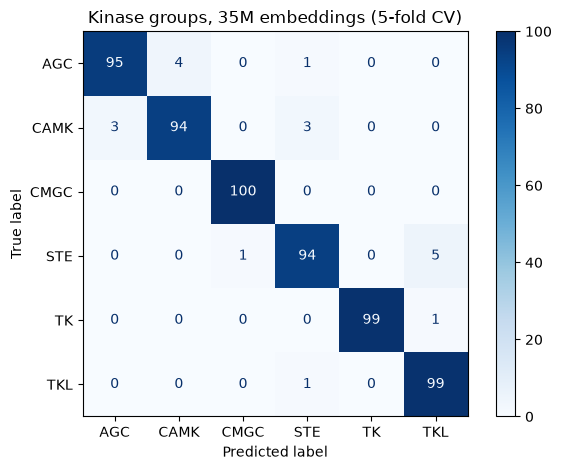

19 / 600 misclassified


,Entry,Protein names,Organism,Length,family,predicted
12,O15530,3-phosphoinositide-dependent protein kinase 1 ...,Homo sapiens (Human),556,AGC,CAMK
22,Q09013,Myotonin-protein kinase (MT-PK) (EC 2.7.11.1) ...,Homo sapiens (Human),629,AGC,CAMK
63,Q8MIT6,Rho-associated protein kinase 1 (EC 2.7.11.39)...,Bos taurus (Bovine),441,AGC,STE
70,O45797,Serine/threonine-protein kinase WARTS homolog ...,Caenorhabditis elegans,908,AGC,CAMK
96,Q9W0V1,3-phosphoinositide-dependent protein kinase 1 ...,Drosophila melanogaster (Fruit fly),836,AGC,CAMK
125,Q9H0K1,Serine/threonine-protein kinase SIK2 (EC 2.7.1...,Homo sapiens (Human),926,CAMK,AGC
168,Q8I113,MAP kinase-interacting serine/threonine-protei...,Caenorhabditis elegans,707,CAMK,AGC
183,G5EED4,Protein nipi-3 (No induction of peptide after ...,Caenorhabditis elegans,655,CAMK,STE
194,O65554,CBL-interacting serine/threonine-protein kinas...,Arabidopsis thaliana (Mouse-ear cress),441,CAMK,AGC
195,P06782,Carbon catabolite-derepressing protein kinase ...,Saccharomyces cerevisiae (strain ATCC 204508 /...,633,CAMK,STE


In [13]:
yk = dk["family"].values
pred = cross_val_predict(probe(), Xk, yk, cv=cv)
ConfusionMatrixDisplay.from_predictions(yk, pred, cmap="Blues")
plt.title("Kinase groups, 35M embeddings (5-fold CV)"); plt.tight_layout(); plt.show()

wrong = dk.loc[pred != yk, ["Entry", "Protein names", "Organism", "Length", "family"]].assign(predicted=pred[pred != yk])
print(f"{len(wrong)} / {len(dk)} misclassified")
wrong.head(15)

## Things to try next

* **Layer choice.** Pass `output_hidden_states=True` and probe each layer. Middle layers sometimes beat the last one.
* **Bigger model.** Add `facebook/esm2_t30_150M_UR50D` to `MODELS`. It is slower on CPU, but check whether Part B improves.
* **Homology-aware split.** Proteins within a family can be near-identical (orthologs from different species), so a
  random split is optimistic. Cluster the sequences (e.g. with MMseqs2 at 30% identity) and keep each cluster entirely
  in train or entirely in test.
* **Other labels.** Predict the EC number's first digit, subcellular location, or the organism's kingdom.
* **Fine-tuning vs. feature extraction.** Unfreeze the model and train end-to-end, then compare the cost and the gain.